<a href="https://colab.research.google.com/github/rania-elfadili/python-IA/blob/main/TP3_Analyse_de_Sentiment_sur_Avis_%C3%89tudiants_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importation biblio pandas pour manipuler les données
import pandas as pd

# Fonction pour charger et explorer les données depuis un fichier CSV
def load_data(filepath):

    # Lecture du fichier CSV avec ';' comme séparateur
    df = pd.read_csv(filepath, sep=';')
    # Affichage des 5 premières lignes pour avoir une idée générale du dataset
    df.head()
    # Comptage du nombre d'avis positifs et négatifs Cela permet de voir si les données sont équilibrées ou non
    df['label'].value_counts()
    # Analyse de la longueur des avis  et describe donne min, max, moyenne, etc.
    df['avis'].str.len().describe()
    # Transformation de la colonne 'avis' en liste de textes
    texts = df['avis'].tolist()
    # Transformation de la colonne 'label' en liste 0 ou 1
    labels = df['label'].tolist()
    # La fonction retourne les textes et leurs labels associés
    return texts, labels

# Ton affiche seulement la liste des textes avec __getitem__(0) qui permet d'accéder au premier élément retourné (texts)
print(load_data('C:\\Users\\rania\\Downloads\\avis_cours.csv').__getitem__(0))
# Stockage des résultats dans deux variables
texts, labels = load_data('C:\\Users\\rania\\Downloads\\avis_cours.csv')

['Le cours est très bien structuré et les explications sont claires', 'J ai beaucoup appris grâce à ce module le professeur est excellent', 'Les exemples donnés en cours sont très pertinents et faciles à comprendre', 'Le professeur prend le temps d expliquer chaque concept en détail', 'Ce cours m a vraiment donné envie d approfondir le sujet', 'Excellent module je le recommande vivement à tous les étudiants', 'Les séances de TP sont très bien organisées et enrichissantes', 'Le professeur est disponible et répond toujours à nos questions', 'J apprécie la pédagogie du professeur il sait rendre le cours vivant', 'Le contenu du cours est riche et bien adapté à notre niveau', 'Les supports de cours sont clairs bien présentés et complets', 'Ce module est l un des meilleurs de la filière vraiment utile', 'Le rythme du cours est bien adapté ni trop rapide ni trop lent', 'Les exercices pratiques permettent de bien consolider les notions théoriques', 'Je suis très satisfait de ce cours j ai prog

In [ ]:
# Importation des bibliothèques nécessaires
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk

# Téléchargement des ressources nécessaires de NLTK
nltk.download('punkt')  # utilisé pour découper le texte en mots (tokenisation)
nltk.download('punkt_tab')  # ressources internes liées à punkt
nltk.download('stopwords')  # liste des mots vides

# Chargement des stopwords en français
stop_fr = set(stopwords.words('french'))

# Fonction pour nettoyer un seul texte
def clean_one(text):

    # Conversion du texte en minuscules pour éviter les doublons
    text = text.lower()
    # Suppression de la ponctuation
    text = re.sub(r'[^\w\s]', '', text)
    # Découpage du texte en mots
    tokens = word_tokenize(text, language='french')
    # Suppression des mots vides
    tokens = [t for t in tokens if t not in stop_fr]
    # Reconstitution du texte nettoyé
    return ' '.join(tokens)

# Fonction pour appliquer le nettoyage à toute la liste de textes
def preprocess(texts):

    # Application de clean_one à chaque texte
    cleaned_texts = [clean_one(t) for t in texts]
    return cleaned_texts

# Application du prétraitement sur tous les textes
texts = preprocess(texts)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\rania\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\rania\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rania\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# Importation de la fonction train_test_split de sklearn
from sklearn.model_selection import train_test_split

# Fonction pour diviser les données
def split_data(texts, labels, test_size=0.2, random_state=42):

    # Séparation des données en 4 parties Xtrain , Xtest , Ytrain , Ytest
    X_train, X_test, y_train, y_test = train_test_split(
        texts, labels,
        test_size=test_size,  # 20% des données pour le test
        random_state=random_state,  # pour avoir toujours le même découpage
        stratify=labels  # permet de garder le même équilibre entre classes soit 0 ou 1
    )

    # Retour des données séparées
    return X_train, X_test, y_train, y_test

# Application de la fonction
X_train, X_test, y_train, y_test = split_data(texts, labels, test_size=0.2, random_state=42)

In [ ]:
# Importation de TF-IDF depuis sklearn
from sklearn.feature_extraction.text import TfidfVectorizer

# Fonction de vectorisation
def vectorize(X_train, X_test, method='tfidf'):

    # Initialisation du vectoriseur TF-IDF
    vec = TfidfVectorizer(
        max_features=500,        # limite à 500 mots les plus importants
        ngram_range=(1,1),       # utilise seulement les mots simples (unigrammes)
        strip_accents='unicode', # supprime les accents (é -> e)
        sublinear_tf=True        # applique une pondération logarithmique
    )
    # Apprentissage du vocabulaire uniquement sur les données d'entraînement
    vec.fit(X_train)
    # Transformation des textes en vecteurs numériques
    X_train_vec = vec.transform(X_train)
    X_test_vec = vec.transform(X_test)
    # Retour des matrices vectorisées
    return X_train_vec, X_test_vec

# affichage du premier vecteur du train et on utilise __getitem__(0)[0] permet d'accéder au premier document vectorisé
print(vectorize(X_train, X_test, method='tfidf').__getitem__(0)[0])
# Affichage du texte original pour comparaison
print(X_train[0])
# Application de la vectorisation
X_train_vec, X_test_vec = vectorize(X_train, X_test, method='tfidf')

  (0, 56)	0.3529456426102012
  (0, 119)	0.17956548337847322
  (0, 198)	0.4176863087964722
  (0, 302)	0.4006572861328825
  (0, 383)	0.4176863087964722
  (0, 430)	0.5032688143098281
  (0, 475)	0.2836479244438373
évaluations beaucoup trop sévères rapport niveau cours


In [ ]:
# Importation du modèle LinearSVC
from sklearn.svm import LinearSVC

# Fonction pour entraîner le classifieur
def train_classifier(X_train, y_train, clf_name='svm'):

    # Création du modèle SVM linéaire
    model = LinearSVC(
        C=1.0,        # paramètre de régularisation (contrôle le compromis biais/variance)
        max_iter=2000 # nombre maximum d'itérations pour éviter les erreurs de convergence
    )
    # Entraînement du modèle avec les données vectorisées
    model.fit(X_train_vec, y_train)
    # Retour du modèle entraîné
    return model

# Appel de la fonction pour entraîner le modèle
model = train_classifier(X_train, y_train, clf_name='svm')

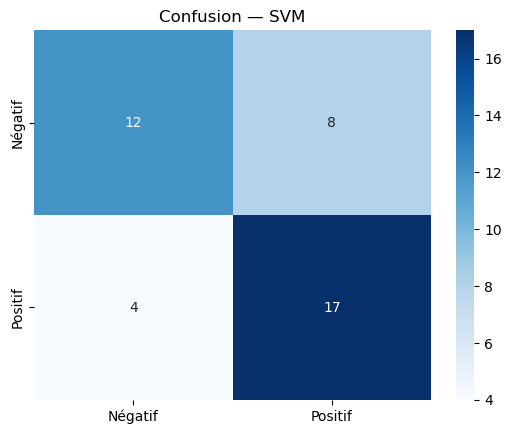

(0.7073170731707317, 0.7391304347826086, 0.68, 0.8095238095238095)


In [ ]:
# Importation des métriques d'évaluation
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,confusion_matrix, classification_report)

# Importation pour la visualisation
import seaborn as sns
import matplotlib.pyplot as plt

# Fonction d'évaluation
def evaluate(model, X_test, y_test, label=''):

    # Prédiction des labels sur les données de test
    y_pred = model.predict(X_test)
    # Calcul des métriques
    accuracy = accuracy_score(y_test, y_pred)   # taux de bonnes prédictions
    f1 = f1_score(y_test, y_pred)               # équilibre entre précision et rappel
    precision = precision_score(y_test, y_pred) # qualité des prédictions positives
    recall = recall_score(y_test, y_pred)       # capacité à retrouver les vrais positifs

    # Affichage du rapport de classification (précision, recall, f1 par classe)
    classification_report(y_test, y_pred, target_names=['Négatif','Positif'])
    # Calcul de la matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    # Affichage de la matrice sous forme de heatmap
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Négatif','Positif'],
        yticklabels=['Négatif','Positif']
    )
    # Titre du graphique
    plt.title(f'Confusion — {label}')
    plt.show()
    # Retour des métriques principales
    return accuracy, f1, precision, recall

# Évaluation du modèle SVM
print(evaluate(model, X_test_vec, y_test, label='SVM'))


In [ ]:
def run_pipeline_classic(vec_method, clf_name):
    """
    Cette fonction permet d'exécuter toute la chaîne de traitement :
    chargement des données → nettoyage → séparation → vectorisation
    → entraînement → évaluation
    """

    # Affichage du pipeline utilisé
    print(f"\n===== Pipeline : {vec_method} + {clf_name} =====")
    # Chargement des données depuis le fichier CSV
    texts, labels = load_data("C:\\Users\\rania\\Downloads\\avis_cours.csv")
    # 2. Prétraitement des textes et on applique une fonction de nettoyage avancée sur chaque texte
    texts = [
        process_text(
            t,
            sentence_tokenizer_type="nltk",   # tokenisation des phrases
            word_tokenizer_type="nltk",       # tokenisation des mots
            operations=["lower", "remove_punctuation"],  # mise en minuscule + suppression ponctuation
            use_stopwords=True,               # suppression des mots vides
            use_pos=False,                    # pas d’analyse grammaticale
            use_stemming=False,               # pas de racinisation
            use_lemmatization=True            # lemmatisation (forme de base des mots)
        )
        for t in texts
    ]

    # Division des données en train et test
    X_train, X_test, y_train, y_test = split_data(texts, labels)
    # Vectorisation
    if vec_method == 'bow':
        # Bag of Words : représentation simple basée sur la fréquence des mots
        X_train_vec, X_test_vec, vectorizer = vectorize_bow(X_train, X_test)

    elif vec_method == 'tfidf':
        # TF-IDF : pondération des mots selon leur importance
        X_train_vec, X_test_vec, vectorizer = vectorize_tfidf(X_train, X_test)

    elif vec_method == 'word2vec':
        # Word2Vec : représentation basée sur le contexte des mots
        X_train_vec, X_test_vec = vectorize_word2vec(X_train, X_test)

    else:
        # Gestion d’erreur si mauvaise méthode
        raise ValueError("Méthode de vectorisation inconnue")

    # Entraînement du modèle (SVM, Naive Bayes, etc.)
    model = train_classifier(X_train_vec, y_train, clf_name)
    # Évaluation du modèle
    accuracy, f1, precision, recall = evaluate(
        model, X_test_vec, y_test, label=f"{vec_method} + {clf_name}"
    )
    #Retour des résultats sous forme de dictionnaire
    return {
        "vectorization": vec_method,
        "classifier": clf_name,
        "accuracy": accuracy,
        "f1_score": f1,
        "precision": precision,
        "recall": recall
    }

In [ ]:
# Liste pour stocker tous les résultats des expériences
results_all = []

# Boucle sur les différentes méthodes de vectorisation
for vec in ['bow', 'tfidf', 'word2vec']:

    # Boucle sur les différents classifieurs
    for clf in ['naive_bayes', 'logistic', 'svm']:
        # Condition pour éviter une combinaison incompatible
        if vec == 'word2vec' and clf == 'naive_bayes':
            continue
        # Exécution du pipeline complet (chargement puis entraînement puis évaluation)
        result = run_pipeline_classic(vec, clf)
        # Ajout du résultat dans la liste
        results_all.append(result)


===== Pipeline : bow + naive_bayes =====

Phrase 1
Texte normalisé : Le cours est très bien structuré et les explications sont claires

Tableau :
{'Token': 'Le', 'Lemma': 'Le'}
{'Token': 'cours', 'Lemma': 'cour'}
{'Token': 'est', 'Lemma': 'est'}
{'Token': 'très', 'Lemma': 'très'}
{'Token': 'bien', 'Lemma': 'bien'}
{'Token': 'structuré', 'Lemma': 'structuré'}
{'Token': 'et', 'Lemma': 'et'}
{'Token': 'les', 'Lemma': 'les'}
{'Token': 'explications', 'Lemma': 'explications'}
{'Token': 'sont', 'Lemma': 'sont'}
{'Token': 'claires', 'Lemma': 'claire'}

Phrase 1
Texte normalisé : J ai beaucoup appris grâce à ce module le professeur est excellent

Tableau :
{'Token': 'J', 'Lemma': 'J'}
{'Token': 'ai', 'Lemma': 'ai'}
{'Token': 'beaucoup', 'Lemma': 'beaucoup'}
{'Token': 'appris', 'Lemma': 'appris'}
{'Token': 'grâce', 'Lemma': 'grâce'}
{'Token': 'à', 'Lemma': 'à'}
{'Token': 'ce', 'Lemma': 'ce'}
{'Token': 'module', 'Lemma': 'module'}
{'Token': 'le', 'Lemma': 'le'}
{'Token': 'professeur', 'Lemma': 

In [ ]:
import pandas as pd

# Vérifier que la liste n'est pas vide
if len(results_all) == 0:
    print("Aucun résultat disponible. Vérifie ton pipeline.")
else:
    df_results = pd.DataFrame(results_all)

    print("Colonnes disponibles :", df_results.columns)

    # Trier seulement si la colonne existe
    if "f1_score" in df_results.columns:
        print(df_results.sort_values(by="f1_score", ascending=False))
    else:
        print("La colonne 'f1_score' n'existe pas")
        print(df_results)